# 3.01 — Contrato de modelado: target, features, partición temporal, baseline y métricas

**Proyecto:** MiBici — TC5044.10 — Equipo 04
**Integración:** Leonardo Santos García
**Decisiones:** Equipo 04 — José Eduardo De Moraes López, Erik Román Cortez, José Emmanuel Vázquez Galán y Leonardo Santos García
**Fecha:** 3 de noviembre de 2026
**Rama:** `feat/phase2-modeling-contract`

> **Problema de negocio:** Pronosticar viajes iniciados por estación y por hora para el día siguiente, con el objetivo de apoyar la planeación del rebalanceo de bicicletas.

Este notebook **no entrena los modelos finales ni hace ajuste de hiperparámetros**: audita `processed_v1`, mide la evidencia necesaria y fija las reglas comunes con las que José Eduardo (`PoissonRegressor`), Erik (`RandomForestRegressor`) y José Emmanuel (`HistGradientBoostingRegressor`) entrenarán y compararán sus modelos. La conclusión final es el **contrato de modelado** del equipo.

## 1. Objetivo

1. Auditar `processed_v1` (periodo, filas, estaciones, columnas, tipos, target y ceros).
2. Clasificar cada columna según su **disponibilidad al momento de pronosticar**.
3. Elegir la estrategia de validación temporal y las fechas de *train*, *validation* y *test*.
4. Definir el baseline común y las métricas.
5. Dejar el contrato de modelado como conclusión.

### 1.1 Punto de partida: decisiones de la Fase 1

| Tema | Decisión | Fuente |
|---|---|---|
| Unidad y target | `departures` por estación × hora de servicio | 1.04, decisiones 1 y 11 |
| Corte | Solo información disponible **antes de las 22:00** del día $d$ | 1.04, decisión 0 |
| Horizonte | Las 20 horas de servicio de $d+1$ (00:00–00:59 y 05:00–23:59) | 1.04, decisión 0 |
| Baseline candidato | Promedio de las últimas 4 semanas, misma estación, día de la semana y hora | 1.04, sección 3.3; ML Canvas v4 |
| Métricas | MAE y WAPE, en total y por segmento (cohorte 2026, eventos extraordinarios) | ML Canvas v4 |
| Solo para evaluar | `is_new_station_cohort`, `is_extraordinary_event` | ML Canvas v4 |

**Pendientes que este notebook debe cerrar:** ventana desde 2022 frente a desde 2023 (decisiones 4–6), posible fuga temporal en las ventanas activas y en las medianas por pareja (1.04, sección 11.2), uso de `station_id` como feature, métrica principal y confirmación del baseline sobre `processed_v1`.

## 2. Auditoría de `processed_v1`

| Archivo | Generado por | Contenido |
|---|---|---|
| `data/processed/station_hour_v1.parquet` | `make processed` | Salidas por estación × hora de servicio, con calendario y antigüedad de la estación |
| `reports/processed/summary.json` | `make processed` | Conteos y distribución del target |
| `reports/processed/decisions.json` | `make processed` | Decisiones aplicadas (corte, ventana, horario, exclusiones) |

In [1]:
import json

import pandas as pd

from mibici.config import PROCESSED_DATA_DIR, REPORTS_DIR

# Load processed_v1 and the reports written by `make processed` (summary and applied decisions)
df = pd.read_parquet(PROCESSED_DATA_DIR / "station_hour_v1.parquet")
summary = json.loads((REPORTS_DIR / "processed" / "summary.json").read_text())
decisions = json.loads((REPORTS_DIR / "processed" / "decisions.json").read_text())

# Size, number of stations, time range and column types
print(f"Filas: {len(df):,} | estaciones: {df['station_id'].nunique()}")
print(f"Periodo: {df['hour_start'].min()} → {df['hour_start'].max()}")
df.dtypes.to_frame("dtype")

2026-11-04 13:44:04.791 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/watson/projects/mibici


Filas: 11,949,160 | estaciones: 473
Periodo: 2022-01-01 00:00:00 → 2026-09-30 23:00:00


,dtype
station_id,int32
hour_start,datetime64[ns]
departures,int32
hour,int32
day_of_week,int32
is_weekend,bool
month,int32
station_age_days,int32
is_new_station_cohort,bool
is_extraordinary_event,bool


In [2]:
# Cross-check the loaded table against the summary written by `make processed`
assert len(df) == summary["n_rows"]
assert df["station_id"].nunique() == summary["n_stations"]
assert not df.duplicated(["station_id", "hour_start"]).any()  # one row per station and hour
assert set(df["hour"].unique()) == {0, *range(5, 24)}  # only the 20 service hours

# Target distribution: share of zeros (mean of a boolean) and key percentiles
zero_share = (df["departures"] == 0).mean()
print(f"Ceros: {zero_share:.1%} (summary: {summary['zero_share']:.1%})")
df["departures"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame("departures")

Ceros: 42.8% (summary: 42.8%)


,departures
count,1.194916e+07
mean,1.698604e+00
std,2.660953e+00
min,0.000000e+00
50%,1.000000e+00
90%,5.000000e+00
99%,1.200000e+01
max,2.050000e+02


**Interpretación**

- Las cuatro afirmaciones se cumplen: la tabla leída coincide con la que registró `make processed` (filas y estaciones), no hay pares estación × hora duplicados y solo aparecen las 20 horas de servicio.
- El target es un **conteo con muchos ceros** (42.8 %), mediana 1, p90 = 5, p99 = 12 y máximo 205: la mayoría de las horas tiene pocas salidas y hay picos raros. Esto pesa en la elección de la métrica (sección 6) y en que las predicciones deben ser ≥ 0.

### 2.1 Disponibilidad de las columnas al pronosticar

Regla: una columna solo puede ser feature si su valor para el día $d+1$ se conoce **antes de las 22:00 del día $d$** (decisión 0).

| Columna | Significado | ¿Se conoce a las 22:00 de $d$? | Decisión | Justificación |
|---|---|---|---|---|
| `departures` | Salidas en la estación y hora | No: es lo que se pronostica | **Target** | — |
| `hour_start` | Inicio de la hora | Sí | **Índice temporal**, no feature | Define el orden y la partición temporal; su información útil ya está en las columnas de calendario |
| `station_id` | Identificador de la estación | Sí | **Llave, no entra al modelo** | Se usa para buscar la historia de cada estación (rezagos por estación y hora) y para devolver cada predicción a su estación. No entra como columna del modelo: es un identificador, no una magnitud; `HistGradientBoostingRegressor` solo admite categorías nativas hasta 255 valores (hay 473); y no aporta información para las estaciones que no aparecen en *train* (≈ 18 % de las filas de *test*). El nivel de cada estación entra a través de su historia (sección 7) |
| `hour` | Hora del día | Sí (calendario) | **Feature** | Picos de 08:00 y 18:00 (1.04, decisión 1). Requiere codificación para el modelo lineal (Poisson) |
| `day_of_week` | Día de la semana | Sí (calendario) | **Feature** | Perfil distinto entre días laborales y fin de semana. Requiere codificación para Poisson |
| `is_weekend` | Sábado o domingo | Sí (calendario) | **Feature** | Redundante con `day_of_week`; se conserva por interpretabilidad (1.04, sección 3.2) |
| `month` | Mes | Sí (calendario) | **Feature** | Estacionalidad anual. Requiere codificación para Poisson |
| `station_age_days` | Días desde la primera actividad observada de la estación | Sí: la primera actividad ocurrió en el pasado | **Feature** | Las estaciones nuevas tienen ≈ 1/3 de la intensidad y maduran con el tiempo (1.04, decisión 8) |
| `is_new_station_cohort` | Estación activa por primera vez desde 2026-01-01 | Sí | **Solo evaluación** | ML Canvas v4: se usa para medir el error por segmento, no como predictor |
| `is_extraordinary_event` | Día con evento extraordinario (bloqueos, huracán) | **No**: un bloqueo no se conoce el día anterior | **Solo evaluación** | Usarlo como predictor sería fuga temporal; se usa para reportar el error con y sin eventos |
| Rezagos ≥ 168 h y promedios estación × día × hora | Aún no existen en `processed_v1` | Sí, si se calculan solo con datos anteriores al corte | **Requiere transformación** | Features candidatas de la Fase 1 (1.04, sección 3.3); se construyen el jueves respetando el corte |

**Limitación (1.04, sección 11.2):** la existencia de cada fila depende de la ventana activa de la estación, que usa su último viaje observado. No afecta a las features, sino a qué filas se evalúan; se revisa al definir la partición (sección 4).

## 3. Distribución temporal

Antes de elegir fechas para *train*, *validation* y *test* se revisa cómo cambian en el tiempo el número de estaciones activas y la intensidad de la demanda. Un corte arbitrario podría dejar en *test* un régimen que el modelo nunca vio.

In [3]:
# Monthly view: active stations, rows, demand and zeros
month = df["hour_start"].dt.to_period("M")
monthly = df.groupby(month).agg(
    stations=("station_id", "nunique"),
    rows=("departures", "size"),
    departures=("departures", "sum"),
    zero_share=("departures", lambda s: (s == 0).mean()),
)
# Demand intensity: average departures per station-hour in each month
monthly["departures_per_row"] = monthly["departures"] / monthly["rows"]
# Stations of the 2026 cohort active in each month (0 before the expansion)
monthly["new_cohort_stations"] = (
    df[df["is_new_station_cohort"]].groupby(month)["station_id"].nunique()
).reindex(monthly.index, fill_value=0)
monthly.index.name = "month"
monthly.style.format(
    {"rows": "{:,}", "departures": "{:,}", "zero_share": "{:.1%}", "departures_per_row": "{:.2f}"}
)

,stations,rows,departures,zero_share,departures_per_row,new_cohort_stations
month,,,,,,
2022-01,300,"186,000","278,857",45.7%,1.50,0
2022-02,300,"168,000","301,126",41.0%,1.79,0
2022-03,300,"186,000","361,706",39.3%,1.94,0
2022-04,300,"180,000","314,425",41.2%,1.75,0
2022-05,300,"186,000","356,873",38.9%,1.92,0
2022-06,300,"180,000","336,162",40.0%,1.87,0
2022-07,300,"186,000","319,450",42.1%,1.72,0
2022-08,300,"186,000","346,086",40.6%,1.86,0
2022-09,300,"180,000","357,565",38.8%,1.99,0


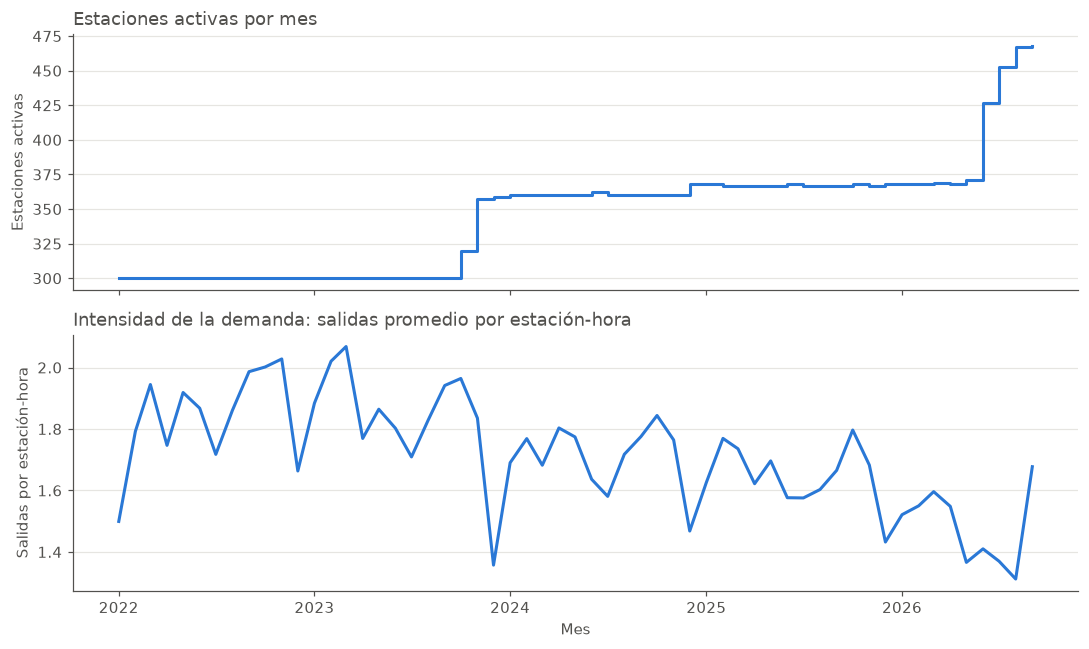

In [4]:
import matplotlib.pyplot as plt

from mibici.config import FIGURES_DIR

SERIES = "#2a78d6"  # same series color as notebook 1.04
MUTED = "#52514e"  # secondary text and axes

# Figure style: thin marks, recessive axes and grid
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
    }
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Active stations and demand intensity by month, saved to reports/figures/
# Two measures with different scales: two panels sharing the time axis (no dual axis)
x = monthly.index.to_timestamp()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.step(x, monthly["stations"], where="post", color=SERIES, linewidth=2)
ax1.set_ylabel("Estaciones activas")
ax1.set_title("Estaciones activas por mes", loc="left", color=MUTED)
ax2.plot(x, monthly["departures_per_row"], color=SERIES, linewidth=2)
ax2.set_ylabel("Salidas por estación-hora")
ax2.set_title(
    "Intensidad de la demanda: salidas promedio por estación-hora", loc="left", color=MUTED
)
ax2.set_xlabel("Mes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "3.01-stations-and-intensity-by-month.png", bbox_inches="tight")
plt.show()

**Interpretación**

- **Tres escalones de estaciones:** 300 estaciones de 2022-01 a 2023-09; ≈ 360–368 desde 2023-10; y la **expansión de 2026**, que pasa de 371 estaciones en mayo a 468 en septiembre (98 estaciones de la cohorte nueva ya en agosto).
- **La intensidad baja durante la expansión:** de ≈ 1.5–1.6 salidas por estación-hora a inicios de 2026 a ≈ 1.31–1.41 entre mayo y agosto, porque las estaciones nuevas tienen menos demanda (1.04, decisión 8). Septiembre de 2026 sube a 1.68 y es el mes con más salidas de todo el periodo (470,925).
- **Diciembre baja cada año** (1.36–1.66), en línea con los festivos de fin de año (1.02).

**Implicaciones para la partición (sección 4):**

1. Los últimos meses contienen un **cambio de régimen**: estaciones sin historia y menor intensidad. El *test* debe incluirlos, porque es el escenario real en el que se usaría el modelo.
2. Si *validation* no contiene estaciones nuevas, los hiperparámetros se eligen sin ver ese régimen; conviene que también incluya meses de la expansión.
3. Una estación con menos de 4 semanas de historia no tiene el baseline de 4 semanas completo: hace falta una regla para esos casos.

## 4. Estrategia de validación temporal

**Pregunta:** ¿basta con una sola partición *train → validation → test* (opción A) o hace falta evaluar en varias ventanas progresivas (opción B), como sugirió el profesor en la retroalimentación de la Fase 1?

| | A. Partición única | B. Ventanas progresivas |
|---|---|---|
| Cómo funciona | Entrenar con el pasado y evaluar una vez en el periodo siguiente | Entrenar hasta el mes $M$, evaluar $M+1$; avanzar $M$ y repetir |
| Ventaja | Un solo entrenamiento por configuración | Mide la estabilidad del error entre periodos |
| Costo | Un solo valor de desempeño, que depende de los meses elegidos | Un entrenamiento por ventana |

Para decidir con evidencia se miden dos cosas, sin entrenar todavía los modelos del equipo:

1. **¿Cuánto cambia el error de un mes a otro?** Se calcula el WAPE mensual de tres reglas simples que no requieren entrenamiento: promedio de las últimas 4 semanas, misma hora de la semana anterior (t-168) y misma hora de hace dos días (t-48). Si el error cambia mucho entre meses, una sola ventana da un valor poco confiable.
2. **¿Cuánto cuesta un entrenamiento?** Se mide el tiempo de un ajuste de `HistGradientBoostingRegressor` sobre el *train* propuesto.

Las reglas usan solo valores anteriores al corte de las 22:00 (rezagos ≥ 48 h). Un rezago solo existe si la estación tenía fila en esa hora pasada; si falta, la regla no se evalúa en esa fila (la cobertura se reporta).

In [5]:
import numpy as np

# Lookup table: departures by (station, hour), used to find each station's own past
departures_by_key = df.set_index(["station_id", "hour_start"])["departures"]


def lagged(hours: int) -> np.ndarray:
    """Departures of the same station `hours` earlier (NaN if that row does not exist)."""
    # Keys are matched by (station_id, hour_start - hours), not by row position
    keys = pd.MultiIndex.from_arrays(
        [df["station_id"], df["hour_start"] - pd.Timedelta(hours=hours)]
    )
    return departures_by_key.reindex(keys).to_numpy(dtype=float)


# Naive rules: all lags are >= 48 h, so they are known before the 22:00 cutoff
weekly = np.vstack([lagged(168 * k) for k in range(1, 5)])  # same hour, 1-4 weeks back
rules = pd.DataFrame(
    {
        "avg_4_weeks": pd.DataFrame(weekly.T).mean(axis=1).to_numpy(),  # skips missing weeks
        "t_168": weekly[0],
        "t_48": lagged(48),
    },
    index=df.index,
)

# Monthly WAPE over the last 12 months, each rule on the rows where it exists
recent = df["hour_start"] >= "2025-10-01"
by_month = df.loc[recent, "hour_start"].dt.to_period("M")
rows = []
for month, idx in by_month.groupby(by_month).groups.items():
    y = df.loc[idx, "departures"]
    row = {"month": str(month)}
    for rule in rules.columns:
        pred = rules.loc[idx, rule]
        ok = pred.notna()  # rows where the rule has a value
        row[rule] = (y[ok] - pred[ok]).abs().sum() / y[ok].sum()  # WAPE
        row[f"{rule}_coverage"] = ok.mean()  # share of rows the rule can forecast
    rows.append(row)
monthly_wape = pd.DataFrame(rows).set_index("month")
monthly_wape["best_rule"] = monthly_wape[rules.columns].idxmin(axis=1)  # lowest WAPE per month
monthly_wape.style.format(precision=3)

,avg_4_weeks,avg_4_weeks_coverage,t_168,t_168_coverage,t_48,t_48_coverage,best_rule
month,,,,,,,
2025-10,0.559,0.999,0.660,0.999,0.789,1.000,avg_4_weeks
2025-11,0.596,1.000,0.705,1.000,0.845,1.000,avg_4_weeks
2025-12,0.710,0.999,0.794,0.999,0.876,1.000,avg_4_weeks
2026-01,0.647,1.000,0.722,1.000,0.848,1.000,avg_4_weeks
2026-02,0.659,1.000,0.775,1.000,0.897,1.000,avg_4_weeks
2026-03,0.602,0.999,0.730,0.999,0.862,1.000,avg_4_weeks
2026-04,0.649,1.000,0.754,1.000,0.845,1.000,avg_4_weeks
2026-05,0.664,0.997,0.786,0.997,0.908,0.998,avg_4_weeks
2026-06,0.714,0.968,0.825,0.968,0.909,0.991,avg_4_weeks


In [6]:
# How much each rule's WAPE changes across months (min, max and range)
monthly_wape[rules.columns].agg(["min", "max"]).T.assign(
    range=lambda t: t["max"] - t["min"]
).style.format(precision=3)

,min,max,range
avg_4_weeks,0.559,0.714,0.154
t_168,0.660,0.825,0.165
t_48,0.789,0.909,0.121


In [7]:
import os
import time

from sklearn.ensemble import HistGradientBoostingRegressor

# Cost of one fit on the proposed train split (default hyperparameters, Poisson loss)
# Diagnostic only: this is not one of the team's models and is not tuned or evaluated
timing_features = ["station_id", "hour", "day_of_week", "month", "station_age_days"]
in_train = df["hour_start"] < "2026-06-01"
X_timing = df.loc[in_train, timing_features].join(rules.loc[in_train, ["avg_4_weeks", "t_168"]])

# Wall-clock time of the fit, with the number of CPUs of the machine that ran it
start = time.perf_counter()
HistGradientBoostingRegressor(loss="poisson", random_state=0).fit(
    X_timing, df.loc[in_train, "departures"]
)
print(
    f"HistGradientBoostingRegressor: {time.perf_counter() - start:.0f} s, "
    f"{len(X_timing):,} filas, {os.cpu_count()} CPU"
)

HistGradientBoostingRegressor: 24 s, 10,869,060 filas, 20 CPU


**Interpretación**

- **El orden de las reglas no cambia:** en los 12 meses gana el promedio de 4 semanas, después t-168 y al final t-48. Entre ellas hay ≈ 0.10 de WAPE de diferencia, y con esa distancia una sola ventana elige bien.
- **El nivel del error sí cambia:** el WAPE del promedio de 4 semanas va de ≈ 0.56 a ≈ 0.71 según el mes. Los meses más difíciles son **diciembre** (festivos) y **junio de 2026** (inicio de la expansión, con la cobertura más baja porque las estaciones nuevas aún no tienen historia). Un solo valor de validación depende de los meses que le toquen.
- **Todos los modelos se evalúan en los mismos meses**, pero los meses son muy distintos entre sí (festivos, expansión). Los tres modelos del equipo probablemente queden más cerca entre sí que estas reglas, y entonces el ganador de un solo periodo puede depender del tipo de mes: un modelo puede manejar mejor las estaciones nuevas y otro los meses normales. Con dos periodos se comprueba si el mismo modelo gana en ambos o si están empatados.
- **Costo:** un ajuste de HGB sobre el *train* completo tarda segundos en la máquina de integración (DGX). Random Forest es más costoso y el hardware del resto del equipo se desconoce, así que repetir la búsqueda de hiperparámetros en varias ventanas no es viable en el tiempo de la Fase 2.

### 4.1 Decisión: partición única para el ajuste y dos ventanas mensuales para comparar

| Elemento | Contenido |
|---|---|
| **Decisión** | **A** para el ajuste de hiperparámetros de cada modelo (*train* → *validation*). **B con dos ventanas mensuales** (junio y julio de 2026) solo para la mejor configuración de cada modelo y el baseline. *Test* reservado para una sola evaluación final |
| **Evidencia** | 4: el orden de las reglas se mantiene en 12 meses, pero su error varía ≈ 0.15 entre meses; un ajuste de HGB tarda segundos en la DGX |
| **Justificación** | Una ventana basta para elegir dentro de un modelo; comparar modelos cercanos y estimar el desempeño futuro requiere más de una ventana. Partir *validation* en dos meses agrega **un solo entrenamiento por modelo**: la ventana de junio coincide con el ajuste de A |
| **Limitación** | Dos ventanas dan una idea de la estabilidad, no una distribución del error; no cubren diciembre. El costo de Random Forest en las máquinas del equipo sigue pendiente (plan operativo, sección 15) |
| **Implementación** | Fechas de la sección 4.2; las ventanas adicionales las ejecuta el integrador en la DGX |

El inicio de *train* se mantiene en **2022-01-01**, la ventana de `processed_v1` (1.04, decisiones 4–6). La comparación contra un *train* desde 2023-01-01, pendiente desde la Fase 1, se ejecuta como un experimento adicional.

In [8]:
# Temporal splits: [start, end) dates, end not included
SPLITS = {
    "train": ("2022-01-01", "2026-06-01"),
    "validation": ("2026-06-01", "2026-08-01"),
    "test": ("2026-08-01", "2026-10-01"),
}
# Stability windows: train up to `train_end`, evaluate the following month
WINDOWS = {
    "window_1": {"train_end": "2026-06-01", "eval": ("2026-06-01", "2026-07-01")},
    "window_2": {"train_end": "2026-07-01", "eval": ("2026-07-01", "2026-08-01")},
}

# Label every row with its split according to its hour_start
split = pd.Series(pd.NA, index=df.index, dtype="string")
for name, (start, end) in SPLITS.items():
    split[(df["hour_start"] >= start) & (df["hour_start"] < end)] = name

assert split.notna().all()  # every row belongs to exactly one split
# Splits are ordered in time: each one ends before the next one starts
by_split = df.groupby(split)["hour_start"].agg(["min", "max"]).loc[list(SPLITS)]
assert (by_split["max"].iloc[:-1].to_numpy() < by_split["min"].iloc[1:].to_numpy()).all()

# Size and composition of each split; "unseen" = stations with no rows in train
train_stations = set(df.loc[split == "train", "station_id"])
summary_splits = (
    df.groupby(split)
    .agg(
        start=("hour_start", "min"),
        end=("hour_start", "max"),
        rows=("departures", "size"),
        stations=("station_id", "nunique"),
        zero_share=("departures", lambda s: (s == 0).mean()),
        new_cohort_stations=(
            "station_id",
            lambda s: s[df.loc[s.index, "is_new_station_cohort"]].nunique(),
        ),
        rows_unseen_in_train=("station_id", lambda s: (~s.isin(train_stations)).mean()),
    )
    .loc[list(SPLITS)]
)
summary_splits.style.format(
    {"rows": "{:,}", "zero_share": "{:.1%}", "rows_unseen_in_train": "{:.1%}"}
)

,start,end,rows,stations,zero_share,new_cohort_stations,rows_unseen_in_train
train,2022-01-01 00:00:00,2026-05-31 23:00:00,"10,869,060",385,42.3%,12,0.0%
validation,2026-06-01 00:00:00,2026-07-31 23:00:00,"511,960",454,48.7%,86,9.4%
test,2026-08-01 00:00:00,2026-09-30 23:00:00,"568,140",469,47.5%,98,18.1%


### 4.2 Fechas

| Conjunto | Fechas | Uso |
|---|---|---|
| *Train* | 2022-01-01 → 2026-05-31 | Entrenamiento |
| *Validation* | 2026-06-01 → 2026-07-31 | Ajuste de hiperparámetros (A) |
| Ventana 1 | *Train* hasta 2026-05-31 → evaluar junio de 2026 | Estabilidad (B) |
| Ventana 2 | *Train* hasta 2026-06-30 → evaluar julio de 2026 | Estabilidad (B) |
| *Test* | 2026-08-01 → 2026-09-30 | Evaluación final, una sola vez, reentrenando con *train* + *validation* |

**Interpretación**

- Los tres conjuntos son disjuntos y ordenados en el tiempo (las afirmaciones de la celda anterior se cumplen).
- *Validation* y *test* caen en la expansión de 2026: el ajuste y la evaluación final ven estaciones nuevas, que es el escenario real de uso. En *test*, ≈ 18 % de las filas son de estaciones que no aparecen en *train*.
- Cada conjunto de evaluación cubre dos meses, así que cada día de la semana aparece ≈ 8 veces.
- No se deja un hueco entre conjuntos: las features con rezagos solo miran hacia atrás desde el corte de las 22:00.

## 5. Baseline común

**Baseline:** promedio de las salidas de la **misma estación, mismo día de la semana y misma hora** en las **últimas 4 semanas** (rezagos de 168, 336, 504 y 672 h).

$$\hat{y}_{s,t} = \frac{1}{|K_{s,t}|}\sum_{k \in K_{s,t}} y_{s,\,t-168k}$$

- $\hat{y}_{s,t}$: salidas pronosticadas para la estación $s$ en la hora $t$.
- $K_{s,t} \subseteq \{1, 2, 3, 4\}$: semanas anteriores en las que la estación tenía fila (estaba activa).
- Todos los rezagos son ≥ 168 h, así que se conocen antes del corte de las 22:00 del día anterior.

Ejemplo: si la estación 2 tuvo 3, 5, 4 y 0 salidas los últimos cuatro jueves a las 08:00, el pronóstico para este jueves a las 08:00 es $(3+5+4+0)/4 = 3$.

**Estaciones sin historia.** Una estación que abrió hace menos de una semana no tiene ninguna de las 4 semanas ($K_{s,t}$ vacío). Para no excluirla de la evaluación ni inventar un 0, se usa en orden:

1. el promedio de las semanas que sí tenga (1 a 3);
2. si no tiene ninguna: el promedio de las **estaciones jóvenes** (menos de 28 días de antigüedad) en la misma hora de las 4 semanas anteriores;
3. si tampoco existe: el promedio de **todas las estaciones** en la misma hora de las 4 semanas anteriores.

Todos los niveles usan solo horas anteriores en ≥ 168 h y `station_age_days`, que es una feature permitida (sección 2.1).

**Evaluación:** solo en *validation* y en sus dos ventanas mensuales. El *test* no se toca (sección 4.1).

In [9]:
# Baseline: own 4-week average, then young stations, then all stations (same hour, 1-4 weeks back)
YOUNG_DAYS = 28


def weekly_average(hourly: pd.Series) -> pd.Series:
    """Mean of a series indexed by hour_start at the same hour 1-4 weeks before each row."""
    weeks = [
        hourly.reindex(df["hour_start"] - pd.Timedelta(hours=168 * k)).to_numpy()
        for k in range(1, 5)
    ]
    return pd.DataFrame(np.vstack(weeks).T, index=df.index).mean(axis=1)  # skips missing weeks


# Fallback levels: hourly mean of young stations (< 28 days old) and of all stations
young = df["station_age_days"] < YOUNG_DAYS
young_average = weekly_average(df[young].groupby("hour_start")["departures"].mean())
all_average = weekly_average(df.groupby("hour_start")["departures"].mean())

# Use the station's own history first; fill the gaps with the fallback levels in order
own_average = rules["avg_4_weeks"]
baseline = own_average.fillna(young_average).fillna(all_average)
# Record which level produced each forecast
baseline_source = pd.Series(
    np.select(
        [own_average.notna(), young_average.notna()],
        ["own_history", "young_stations"],
        default="all_stations",
    ),
    index=df.index,
)
# The first 4 weeks of processed_v1 have no history; every later row gets a forecast
has_history = df["hour_start"] >= df["hour_start"].min() + pd.Timedelta(weeks=4)
assert baseline[has_history].notna().all()
assert (baseline[has_history] >= 0).all()  # counts cannot be negative

# Share of validation rows forecast by each level
in_validation = split == "validation"
baseline_source[in_validation].value_counts(normalize=True).to_frame("share").style.format(
    "{:.2%}"
)

,share
own_history,97.64%
young_stations,2.36%


In [10]:
def mae(y: pd.Series, y_pred: pd.Series) -> float:
    """Mean absolute error, in departures per station-hour."""
    return (y - y_pred).abs().mean()


def wape(y: pd.Series, y_pred: pd.Series) -> float:
    """Total absolute error as a share of total departures."""
    return (y - y_pred).abs().sum() / y.sum()


def in_period(start: str, end: str) -> pd.Series:
    """Rows whose hour_start falls in [start, end)."""
    return (df["hour_start"] >= start) & (df["hour_start"] < end)


# Evaluation periods (validation and its two monthly windows); test is not used here
periods = {
    "validation": in_validation,
    "window_1 (2026-06)": in_period(*WINDOWS["window_1"]["eval"]),
    "window_2 (2026-07)": in_period(*WINDOWS["window_2"]["eval"]),
}
# Segments required by the ML Canvas: all rows, established stations and the 2026 cohort
segments = {
    "all": pd.Series(True, index=df.index),
    "established_stations": ~df["is_new_station_cohort"],
    "new_station_cohort": df["is_new_station_cohort"],
}
# Baseline MAE and WAPE for every period x segment combination
rows = []
for period, in_p in periods.items():
    for segment, in_s in segments.items():
        mask = in_p & in_s
        y, y_pred = df.loc[mask, "departures"], baseline[mask]
        rows.append(
            {
                "period": period,
                "segment": segment,
                "rows": int(mask.sum()),
                "MAE": mae(y, y_pred),
                "WAPE": wape(y, y_pred),
            }
        )
baseline_scores = pd.DataFrame(rows).set_index(["period", "segment"])
# Extraordinary events cannot be evaluated as a segment if validation has none
print(
    "Filas con evento extraordinario en validation:",
    int(df.loc[in_validation, "is_extraordinary_event"].sum()),
)
baseline_scores.style.format({"rows": "{:,}", "MAE": "{:.3f}", "WAPE": "{:.3f}"})

Filas con evento extraordinario en validation: 0


**Interpretación**

- **Cobertura completa:** en *validation*, el 97.6 % de las filas usa la historia propia de la estación y el 2.4 % el promedio de las estaciones jóvenes; el tercer nivel (todas las estaciones) no fue necesario.
- **Marca a superar en *validation*:** MAE = 0.967 salidas por estación-hora y WAPE = 0.696. Por ventana: junio 0.723 y julio 0.672 de WAPE, consistente con la sección 4 (junio es el mes más difícil).
- **Estaciones nuevas:** WAPE ≈ 1.10, es decir, **peor que pronosticar siempre 0** en términos de WAPE (que daría 1.0). Su MAE es bajo (0.54) porque tienen pocas salidas, pero el error relativo es grande: el baseline no sabe pronosticar estaciones que apenas empiezan. Es el segmento donde los modelos, con `station_age_days`, pueden aportar más.
- **Eventos extraordinarios:** *validation* no contiene ninguno (el último fue en febrero de 2026), así que ese segmento no puede evaluarse ahí. Se reporta si aparece en *test*.

### 5.1 Decisión: baseline común

| Elemento | Contenido |
|---|---|
| **Decisión** | Baseline = promedio de las últimas 4 semanas, misma estación, día y hora; con respaldo de estaciones jóvenes y de todas las estaciones cuando no hay historia propia |
| **Evidencia** | 1.04, sección 3.3 (mejor regla simple en la Fase 1); sección 4 (mejor regla en los 12 meses recientes); sección 5 (cubre el 100 % de *validation*) |
| **Justificación** | Es simple, solo usa información anterior al corte y es la regla más difícil de superar entre las evaluadas. Los niveles de respaldo evitan excluir las estaciones nuevas o inventarles un 0 |
| **Limitación** | Es débil en las estaciones nuevas (WAPE ≈ 1.10). El umbral de 28 días para "estación joven" es una convención, no un valor optimizado |
| **Implementación** | Jueves: se mueve a `mibici/` como estimador con interfaz de scikit-learn (`fit` / `predict`), con pruebas (plan operativo, sección 7.1) |

**Marca que deben superar los modelos** (en las mismas filas y periodos):

| Periodo | MAE | WAPE |
|---|---|---|
| *Validation* (jun–jul 2026) | 0.967 | 0.696 |
| Ventana 1 (jun 2026) | 1.019 | 0.723 |
| Ventana 2 (jul 2026) | 0.921 | 0.672 |

## 6. Métricas comunes

| Métrica | Fórmula | Lectura |
|---|---|---|
| **MAE** | $\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert$ | Error promedio en **bicicletas** por estación-hora |
| **WAPE** | $\text{WAPE} = \frac{\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert}{\sum_{i=1}^{n} y_i}$ | Error total como **proporción** de las salidas observadas |

- $y_i$: salidas observadas en la fila $i$ (estación × hora); $\hat{y}_i$: salidas pronosticadas; $n$: número de filas evaluadas.
- Las dos funcionan con ceros en el target (a diferencia del MAPE, que divide entre cada $y_i$).

**Relación entre ambas:** $\text{WAPE} = \text{MAE} \times \dfrac{n}{\sum y_i}$. En las mismas filas, $n$ y $\sum y_i$ son iguales para todos los modelos, así que **MAE y WAPE ordenan a los modelos igual**. Solo difieren al comparar periodos o segmentos con distinto volumen de salidas. La siguiente celda lo comprueba con el baseline.

In [11]:
# WAPE = MAE * n / sum(y): same ranking within a period, different scale across periods
# Total departures (sum of y) of every period x segment combination
volume = pd.Series(
    {
        (period, segment): df.loc[in_p & in_s, "departures"].sum()
        for period, in_p in periods.items()
        for segment, in_s in segments.items()
    }
)
# Recompute WAPE from MAE and check that both match
check = baseline_scores.assign(
    departures=volume,
    wape_from_mae=lambda t: t["MAE"] * t["rows"] / t["departures"],
)
assert np.allclose(check["WAPE"], check["wape_from_mae"])
check[["rows", "departures", "MAE", "WAPE"]].style.format(
    {"rows": "{:,}", "departures": "{:,}", "MAE": "{:.3f}", "WAPE": "{:.3f}"}
)

**Interpretación**

- La identidad se cumple en todos los periodos y segmentos.
- **El MAE engaña al comparar grupos con distinto volumen:** las estaciones nuevas tienen el MAE más bajo (≈ 0.5) porque tienen pocas salidas, pero su WAPE (≈ 1.10) muestra que son las peor pronosticadas. El WAPE sí permite comparar ventanas y segmentos.

### 6.1 Decisión: métricas y predicciones no negativas

| Elemento | Contenido |
|---|---|
| **Decisión** | **WAPE como métrica principal** y **MAE como secundaria**, reportadas siempre juntas, en *validation*, en cada ventana y por segmento (estaciones consolidadas, cohorte nueva y, cuando existan, eventos extraordinarios). El pipeline común **recorta las predicciones a 0**; la pérdida de `HistGradientBoostingRegressor` la elige su responsable en el ajuste (`loss="poisson"` es la natural para conteos) |
| **Evidencia** | Sección 6: en las mismas filas ambas ordenan igual, y el MAE no es comparable entre grupos con distinto volumen. 1.04, sección 3.3 y ML Canvas v4: el WAPE ya se usó para comparar reglas y está en el criterio de despliegue |
| **Justificación** | El WAPE es comparable entre meses y segmentos, que es lo que exigen la estabilidad (sección 4) y la evaluación por segmento del ML Canvas. El MAE se lee en bicicletas, la unidad de la operación de rebalanceo. Un conteo negativo no tiene sentido operativo; `PoissonRegressor` y `RandomForestRegressor` no producen negativos, `HistGradientBoostingRegressor` con `squared_error` sí |
| **Limitación** | El WAPE pondera por volumen: las estaciones con más salidas pesan más en el total, y un error en una estación pequeña casi no cuenta (por eso se reporta la cohorte nueva aparte). Recortar a 0 corrige el síntoma, no el sesgo de un modelo que predice negativos |
| **Implementación** | Jueves: funciones `mae` y `wape` y el recorte a 0 en `mibici/`, con las pruebas del plan operativo (sección 7.1) |

## 7. Conclusión: contrato de modelado

Este contrato es la referencia única para entrenar y comparar los modelos de la Fase 2. Ningún integrante cambia el target, las features, las fechas, el baseline ni las métricas en su experimento; cualquier cambio se propone al equipo y se documenta.

### 7.1 Problema

| Elemento | Definición |
|---|---|
| Pregunta de negocio | ¿Cuántos viajes se iniciarán en cada estación y en cada hora del día siguiente, para apoyar la planeación del rebalanceo de bicicletas? |
| Tipo | Regresión de conteos; un modelo global para todas las estaciones |
| Datos | `processed_v1` (`data/processed/station_hour_v1.parquet`, `make processed`) |
| Unidad | Estación × hora de servicio (00:00–00:59 y 05:00–23:59) |
| Target | `departures` (entero ≥ 0) |
| Corte | Solo información disponible **antes de las 22:00 del día $d$** |
| Horizonte | Las 20 horas de servicio del día $d+1$ |

### 7.2 Features comunes

| Grupo | Columnas | Disponible al corte porque… |
|---|---|---|
| Calendario | `hour`, `day_of_week`, `is_weekend`, `month` | Se conocen de antemano |
| Estación | `station_age_days` | La primera actividad de la estación ya ocurrió |
| Historia de la estación | `avg_4_weeks`: promedio de las últimas 4 semanas, misma estación, día y hora, con los respaldos de la sección 5 (estaciones jóvenes y todas las estaciones) | Rezagos ≥ 168 h |
| | `t_168`: salidas de la misma estación y hora una semana antes (vacío si la estación no existía) | Rezago de 168 h |

- `station_id` es la **llave** para construir la historia y devolver las predicciones; no entra al modelo (sección 2.1).
- `is_new_station_cohort` e `is_extraordinary_event` son **solo para evaluar** por segmento.
- La codificación de `hour`, `day_of_week` y `month` para `PoissonRegressor` (categorías o seno/coseno) la decide su responsable en el ajuste; los modelos de árboles las usan sin codificar.

### 7.3 Partición temporal

| Conjunto | Fechas | Uso |
|---|---|---|
| *Train* | 2022-01-01 → 2026-05-31 | Entrenamiento |
| *Validation* | 2026-06-01 → 2026-07-31 | Ajuste de hiperparámetros |
| Ventana 1 | *Train* hasta 2026-05-31 → evaluar 2026-06 | Estabilidad (mejor configuración de cada modelo) |
| Ventana 2 | *Train* hasta 2026-06-30 → evaluar 2026-07 | Estabilidad (mejor configuración de cada modelo) |
| *Test* | 2026-08-01 → 2026-09-30 | Evaluación final, **una sola vez**, reentrenando con *train* + *validation* |

### 7.4 Baseline

Promedio de las últimas 4 semanas, misma estación, día de la semana y hora, con respaldo de estaciones jóvenes (< 28 días) y de todas las estaciones (sección 5).

| Periodo | MAE | WAPE |
|---|---|---|
| *Validation* | 0.967 | 0.696 |
| Ventana 1 (jun 2026) | 1.019 | 0.723 |
| Ventana 2 (jul 2026) | 0.921 | 0.672 |

### 7.5 Métricas

- **Principal: WAPE.** **Secundaria: MAE.** Se reportan siempre juntas.
- Por periodo (*validation*, ventana 1, ventana 2 y, al final, *test*) y por segmento: todas las filas, estaciones consolidadas, cohorte nueva y, cuando existan, eventos extraordinarios.
- Las predicciones se recortan a 0 en el pipeline común.

### 7.6 Reglas de comparación

1. Mismos datos, features, fechas, baseline y métricas para todos los modelos.
2. Los hiperparámetros se eligen **solo con *validation***; el *test* no se usa para ninguna decisión.
3. Un modelo es candidato si supera al baseline en WAPE en *validation* y en las dos ventanas; también se revisa la cohorte nueva (criterio de despliegue del ML Canvas v4).
4. Entre candidatos se prefiere el que gana en las dos ventanas; si cada uno gana en una, se reportan como empatados y se decide con el WAPE de *validation* y la cohorte nueva.
5. Cada corrida se registra en MLflow con el nombre del modelo, los hiperparámetros, las fechas de cada conjunto, las métricas por periodo y segmento, el baseline correspondiente y el commit de Git.
6. Semilla fija (`random_state`) en todo estimador que la acepte.

### 7.7 Modelos asignados

| Integrante | Modelo | Justificación |
|---|---|---|
| José Eduardo De Moraes López | `PoissonRegressor` | Modelo lineal generalizado para conteos no negativos; referencia estadística |
| Erik Román Cortez | `RandomForestRegressor` | Relaciones no lineales e interacciones sin forma funcional fija |
| José Emmanuel Vázquez Galán | `HistGradientBoostingRegressor` | Boosting eficiente para muchas filas; la pérdida (`loss`) se elige en el ajuste |

### 7.8 Pendientes y limitaciones

| Tema | Estado |
|---|---|
| Hardware del equipo | Se consultó; la regla común de cómputo (por ejemplo, submuestreo para el ajuste) se define con esa información y debe ser la misma para los tres modelos |
| *Train* desde 2023 frente a 2022 (1.04, decisiones 4–6) | Experimento adicional con la misma configuración, registrado en MLflow |
| Ventanas activas y medianas por pareja (1.04, sección 11.2) | Limitación documentada: afectan qué filas existen y qué viajes cuentan en el target, no las features |
| Comportamientos propios de una estación que su historia reciente no muestra | Limitación de no usar `station_id`; la ubicación de la estación (latitud y longitud) es un experimento posible en la Fase 3 |
| Umbral de 28 días para "estación joven" en el baseline | Convención, no un valor optimizado |

## Declaración de uso de inteligencia artificial

En la elaboración de este notebook se utilizaron las siguientes herramientas de IA:

- Anthropic. (2026). *Claude Opus 5.5* [Modelo de lenguaje grande], mediante Claude Code (extensión de VS Code). Utilizado para **generación de código** (celdas de auditoría, distribución temporal, comparación de reglas simples, partición temporal, baseline y métricas), **verificación de resultados** (ejecución completa del notebook y Ruff) y **redacción preliminar** de las interpretaciones, las tablas de decisión y el contrato de modelado. https://claude.com/claude-code
- OpenAI. (2026). *ChatGPT (basado en GPT Sol 5.6)* [Modelo de lenguaje grande]. Utilizado para **planeación del trabajo** y **definición de las tareas** del contrato de modelado. https://chat.openai.com/

Las decisiones de este notebook (estrategia de validación, fechas, features, baseline, métricas y reglas de comparación) fueron tomadas y aprobadas por el integrador (Leonardo Santos García) a partir de la evidencia mostrada en cada sección. Todo el contenido generado fue revisado, ejecutado y validado por el integrador; el equipo asume la responsabilidad final de lo entregado.